# ПР-1. Настройка окружения и первичный анализ данных
**Датасет:** Give Me Some Credit (Kaggle) — кредитный скоринг.
**Почему выбран:** тема финансового риска подходит для итогового проекта, в данных есть пропуски, выбросы и дисбаланс классов, что позволяет выполнить все последующие работы.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

print(os.getcwd())

df = pd.read_csv("../data/cs-training.csv", index_col=0)
df.head()

c:\Users\user\.vscode\MLSU\credit-risk-ml\notebooks


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [2]:
df.shape

(150000, 11)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

In [4]:
df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [5]:
df.isnull().sum()

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

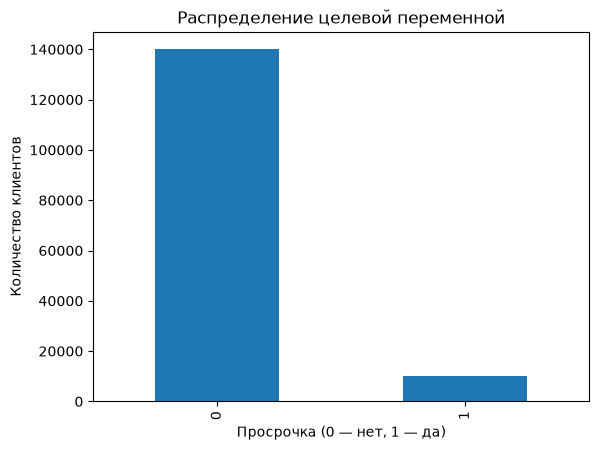

In [6]:
df["SeriousDlqin2yrs"].value_counts().plot(kind="bar")
plt.title("Распределение целевой переменной")
plt.xlabel("Просрочка (0 — нет, 1 — да)")
plt.ylabel("Количество клиентов")
plt.show()

На графике видно, что клиентов без просрочки намного больше, чем клиентов с просрочкой. Просрочку допустили только около 6,7% клиентов. Это называется дисбалансом классов.

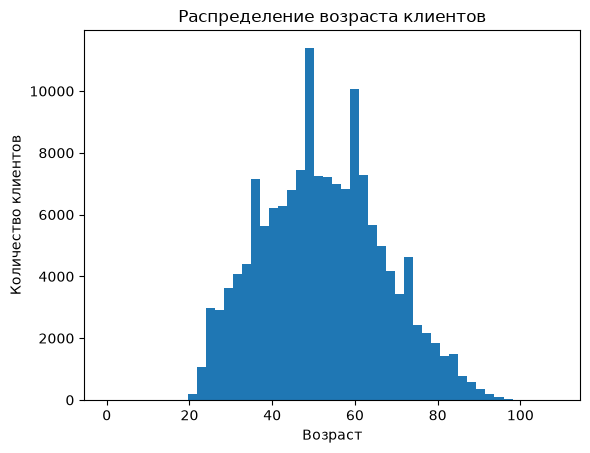

In [7]:
df["age"].plot(kind="hist", bins=50)
plt.title("Распределение возраста клиентов")
plt.xlabel("Возраст")
plt.ylabel("Количество клиентов")
plt.show()

Основная масса клиентов имеет возраст примерно от 30 до 70 лет, средний возраст около 52 лет. Есть значение возраста 0, это ошибка в данных, её нужно будет исправить или убрать.

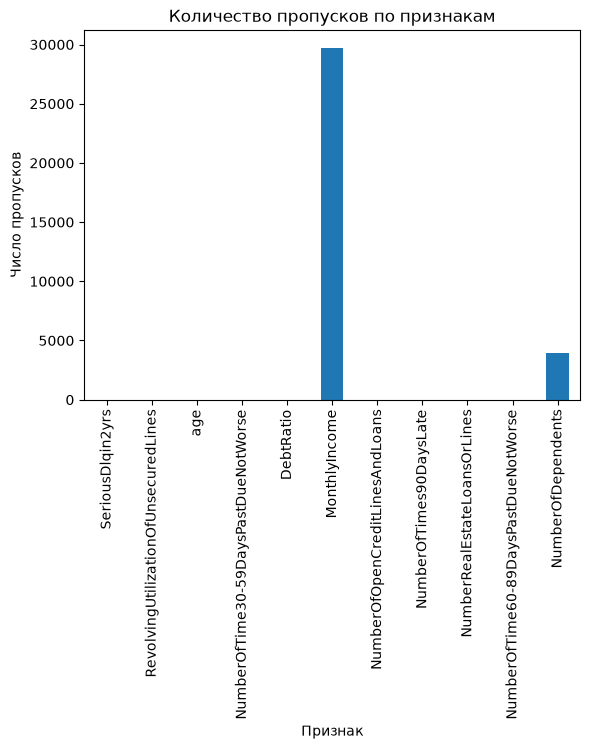

In [8]:
df.isnull().sum().plot(kind="bar")
plt.title("Количество пропусков по признакам")
plt.xlabel("Признак")
plt.ylabel("Число пропусков")
plt.show()

Пропуски есть только в двух столбцах: в доходе (MonthlyIncome) не хватает около 30 тысяч значений (примерно 20%), а в числе иждивенцев (NumberOfDependents) около 4 тысяч (примерно 2,6%). Остальные столбцы заполнены полностью.

## Наблюдения
1. **Дисбаланс классов.** Только около 6,7% клиентов имеют серьёзную просрочку (соотношение примерно 1:14), поэтому accuracy будет плохой метрикой: модель, всегда предсказывающая «нет просрочки», получит около 93% точности.
2. **Пропуски.** Около 20% значений `MonthlyIncome` и 2,6% `NumberOfDependents` отсутствуют. Выбор способа заполнения нужно обосновать на этапе предобработки (ПР-3).
3. **Выбросы и аномалии.** У `RevolvingUtilizationOfUnsecuredLines` и `DebtRatio` максимумы на порядки больше медианы, в `age` есть значение 0, а в признаках просрочек встречается значение 98. Их нужно изучить в ПР-2 до принятия решения об удалении или замене.

**Вывод:** датасет подходит для всех последующих работ, так как содержит реальные дефекты данных, дисбаланс и числовую целевую переменную для регрессии (`MonthlyIncome`).

In [9]:
print("Возраст = 0:", (df["age"] == 0).sum())
print("Utilization > 1:", (df["RevolvingUtilizationOfUnsecuredLines"] > 1).sum())
print("Просрочки 96 или 98:", df["NumberOfTimes90DaysLate"].isin([96, 98]).sum())
print("Доля дефолтов:", df["SeriousDlqin2yrs"].mean())

Возраст = 0: 1
Utilization > 1: 3321
Просрочки 96 или 98: 269
Доля дефолтов: 0.06684
